Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


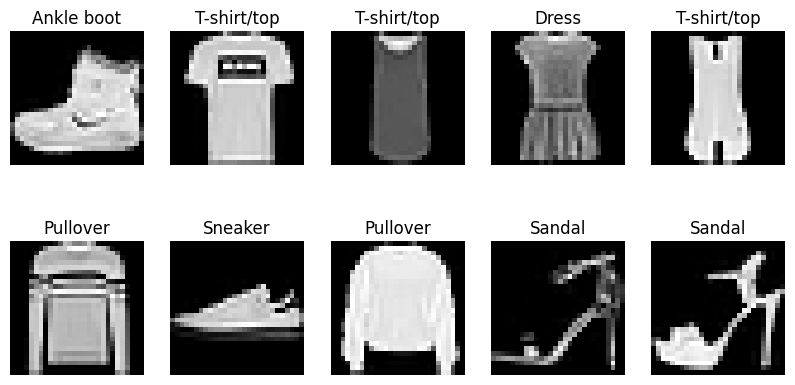

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 58ms/step - accuracy: 0.8193 - loss: 0.5022 - val_accuracy: 0.8741 - val_loss: 0.3530
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 57ms/step - accuracy: 0.8805 - loss: 0.3296 - val_accuracy: 0.8785 - val_loss: 0.3232
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 57ms/step - accuracy: 0.8982 - loss: 0.2822 - val_accuracy: 0.8968 - val_loss: 0.2816
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 58ms/step - accuracy: 0.9086 - loss: 0.2495 - val_accuracy: 0.9044 - val_loss: 0.2652
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 57ms/step - accuracy: 0.9168 - loss: 0.2260 - val_accuracy: 0.8982 - val_loss: 0.2855
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 57ms/step - accuracy: 0.9241 - loss: 0.2057 - val_accuracy: 0.9038 - val_loss: 0.2687
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 57ms/step - accuracy: 0.9323 - loss: 0.1837 - val_accuracy: 0.9136 - val_loss: 0.2461
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 83s 58ms/step - accuracy: 0.9373 - loss: 0.1675 - 

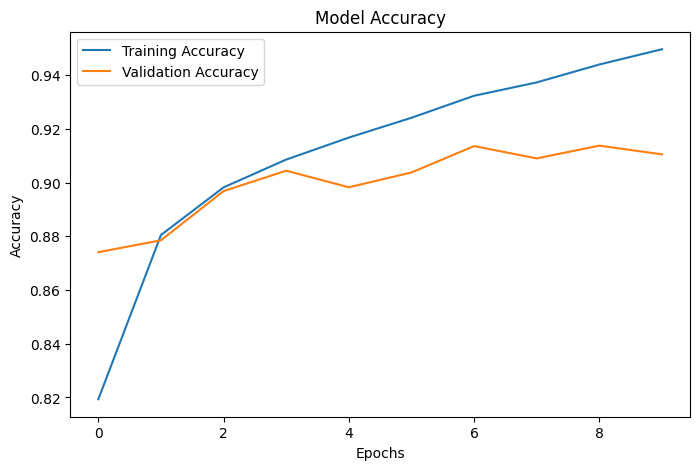

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


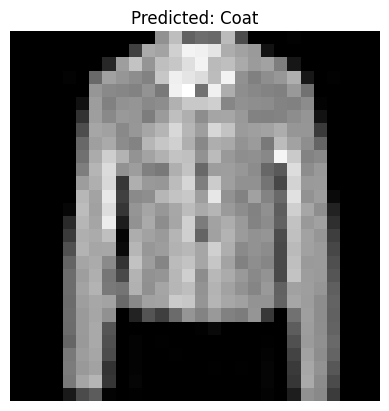

Predicted Category: Coat
Actual Category: Coat
Model saved successfully!


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers

# Load Fashion MNIST dataset

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

class_names = [
    'T-shirt/top',
    'Trouser',
    'Pullover',
    'Dress',
    'Coat',
    'Sandal',
    'Shirt',
    'Sneaker',
    'Bag',
    'Ankle boot'
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.show()

# Normalize training and testing images

x_train = x_train / 255.0
x_test = x_test / 255.0

# Reshape images for CNN model

x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

# Create CNN model

model = keras.Sequential([

    # First convolution layer
    layers.Conv2D(32, (3, 3), activation='relu',
                  input_shape=(28, 28, 1)),

    # Max pooling layer
    layers.MaxPooling2D((2, 2)),

    # Second convolution layer
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Max pooling layer
    layers.MaxPooling2D((2, 2)),

    # Convert into one dimensional data
    layers.Flatten(),

    # Dense layer
    layers.Dense(128, activation='relu'),

    # Output layer with 10 categories
    layers.Dense(10, activation='softmax')
])

model.summary()

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Model Accuracy')

plt.xlabel('Epochs')

plt.ylabel('Accuracy')

plt.legend()

plt.show()

# Predict one test image

predictions = model.predict(x_test)

# Select an image
index = 10

# Get predicted category
predicted_label = np.argmax(predictions[index])

# Get actual category
actual_label = y_test[index]

# Display image
plt.imshow(x_test[index].reshape(28, 28), cmap='gray')

plt.title("Predicted: " + class_names[predicted_label])

plt.axis('off')

plt.show()

print("Predicted Category:", class_names[predicted_label])

print("Actual Category:", class_names[actual_label])

# Save model

model.save('clothing_classification_model.h5')

print("Model saved successfully!")